In [1]:
# Notebooks live in Notebooks/GRUMish/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
for p in [os.getcwd(), os.path.join(os.getcwd(), "Notebooks", "GRUMish")]:
    if p not in sys.path:
        sys.path.insert(0, p)
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# 05 — What can the no-contract model predict? Theory and data

Three questions from the Inbox (26-10-29) and from Nir's paper outline ("predict these properties from the model;
1st vs 2nd order effects"):
1. **Can a perfect fit of the model with no contract tell us what a contract will do?** (the OOD question, and the
   "engineered function" idea: same base preference, totally different behaviour under a contract).
2. **Is the Apple decay predictable** from the no-contract weights?
3. **Can we predict how hard a request is to obey** from the no-contract weights — and does it relate to the feature's
   scale?

In [2]:
from grumish import *
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
setup_plots()
FIG = "figs/GRUMish"
R = load_all()
QG = [m for m in REAL if FAMILY[m] != "olmo"]

## 1. Theory: the no-contract data cannot identify what a contract does

In the GRUM, the utility of laptop *j* under contract *x* is u = (a + Bᵀx)ᵀ z_j. With **no contract, x = 0**, so every
no-contract choice depends on **a only**. B — everything a contract does — multiplies a zero and drops out of the
likelihood. **Any B fits the no-contract data equally well.** A perfect base model therefore predicts nothing about
conditionals; only (i) runs with a contract or (ii) an assumption about B (an inductive bias) can.

The demonstration below builds 5 GRUMs that are **identical with no contract** (they all have qwen-32B's real *a*), and
differ only in B. Then it asks each of them the `8GB` request:
- **real** — the B measured from qwen-32B's actual `ram=8GB` run;
- **ignores it** — B = 0: the request changes nothing;
- **obedient filter** — pushes 8GB to the top, touches nothing else;
- **over-reacts** — pushes 8GB and turns every other taste upside down (κ = 2: HP and 13-inch become the favourites);
- **chaos** — a random B row, three times as large as the real shift.

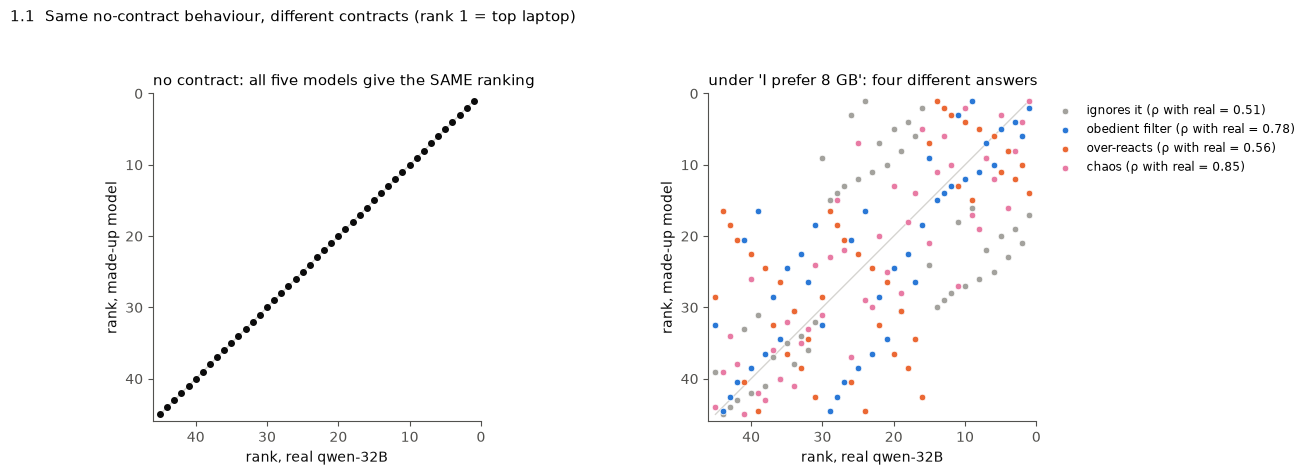

real             top 3 under 8GB: ['ASUS 16in 8GB', 'ASUS 14in 8GB', 'Lenovo 16in 8GB']   rho with real: +1.00
ignores it       top 3 under 8GB: ['Apple 16in 16GB', 'ASUS 16in 16GB', 'Apple 14in 16GB']   rho with real: +0.51
obedient filter  top 3 under 8GB: ['Apple 16in 8GB', 'ASUS 16in 8GB', 'Apple 14in 8GB']   rho with real: +0.78
over-reacts      top 3 under 8GB: ['HP 13in 8GB', 'Dell 13in 8GB', 'Lenovo 13in 8GB']   rho with real: +0.56
chaos            top 3 under 8GB: ['ASUS 16in 8GB', 'ASUS 13in 8GB', 'Dell 16in 8GB']   rho with real: +0.85


In [3]:
m = "qwen-32B"; a = R[(m, "none")].w; real = R[(m, "ram=8GB")].w
rng = np.random.default_rng(3)
def made_up(rho, kappa):
    return predict_struct(a, {"sigma": {"ram": 1.0}, "rho": {"ram": rho}, "kappa": {("ram", g): kappa for g in FEATS}}, {"ram": "8GB"}, shape="peak")
noise = pd.Series(rng.normal(0, 3 * (real - a).std(), len(a)), index=a.index)
for f in FEATS: noise[f] = (noise[f] - noise[f].mean()).values
MOD = {"real": real, "ignores it": a, "obedient filter": made_up(30, 0.0), "over-reacts": made_up(30, 2.0), "chaos": a + noise}
cols = {"real": INK, "ignores it": GRAY, "obedient filter": BLUE, "over-reacts": ORANGE, "chaos": MAGENTA}
u0 = additive_utility(a); ureal = additive_utility(real)
rk = lambda u: pd.Series(u).rank(ascending=False).values
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].scatter(rk(u0), rk(u0), s=16, color=INK)
axes[0].set_title("no contract: all five models give the SAME ranking", loc="left")
for name, w in MOD.items():
    if name == "real": continue
    u = additive_utility(w)
    axes[1].scatter(rk(ureal), rk(u), s=22, color=cols[name], edgecolor="white", linewidth=0.5,
                    label=f"{name} (ρ with real = {spearmanr(ureal, u)[0]:.2f})")
axes[1].set_title("under 'I prefer 8 GB': four different answers", loc="left")
for ax in axes:
    ax.plot([1, 45], [1, 45], color=LGRAY, lw=1, zorder=0); ax.set_xlim(46, 0); ax.set_ylim(46, 0); ax.set_aspect("equal")
    ax.set_xlabel("rank, real qwen-32B"); ax.set_ylabel("rank, made-up model")
axes[1].legend(frameon=False, fontsize=8.5, loc="upper left", bbox_to_anchor=(1.02, 1.0))
fig.suptitle("1.1  Same no-contract behaviour, different contracts (rank 1 = top laptop)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.94)); fig.savefig(f"{FIG}/05_1_identification.png", dpi=150); plt.show()
for name, w in MOD.items():
    u = additive_utility(w); top = [lap_name(LAPTOPS[i]) for i in np.argsort(-u)[:3]]
    print(f"{name:16} top 3 under 8GB: {top}   rho with real: {spearmanr(ureal, u)[0]:+.2f}")

- **With no contract the five models cannot be told apart** (left: one ranking). Under `8GB` each has a different
  top 3: real **ASUS 16in 8GB, ASUS 14in 8GB, Lenovo 16in 8GB**; "ignores it" Apple 16in 16GB; "obedient filter"
  Apple 16in 8GB; "over-reacts" HP 13in 8GB.
- **So the answer to the inbox question is no.** A perfect no-contract fit says nothing about conditionals; the B part of
  the GRUM is invisible at x = 0. This is the formal version of "the contract is an OOD shift".
- Note the real winner: not the "obedient filter" guess (Apple) but ASUS. Assuming κ = 0 (a pure filter) misses the
  Apple decay. The inductive bias has to include leakage.
- The Spearman numbers (0.51 … 0.85; even the random B gets 0.85) are a weak test on 45 laptops dominated by RAM; the top
  3 tell the story better.

### So what is our inductive bias?

What the structured GRUM assumes about B, and what notebooks 02–04 found:

| | assumption | evidence | verdict |
|---|---|---|---|
| A1 | a contract acts through the **features** (no per-laptop effects) | oracle 0.947 vs 0.953 for a free utility per laptop (laptops) — books R² 0.26–0.39 | laptops yes, books no |
| A2 | one push ρ and one flattening σ **per feature**, any level | R² 0.85–0.96 over 3 levels | yes |
| A3 | the push has an **ideal-point** shape on ordered features | 13 > 14 > 16 under `13-inch` in 6/7 models; better R² on average | yes |
| A4 | other features are only **shrunk** toward 0 (κ ≤ 1), never turned | brand **turns** under every RAM request (Apple 1st → 5th); screen turns under `4GB` | **no** — κ > 1 is common |
| A5 | leakage goes **down** the priority order only (RAM → screen → brand) | brand → RAM 0.48–0.51 with all-pairs weights (0.16–0.20 with CP) | **no** for choices: the requested feature moves to the top of the priority order |
| A6 | requirements combine as a **diluted sum** | 0.91–0.92 pair accuracy (notebook 04) | yes, plus a bonus for meeting all |

Under these assumptions, one run per feature plus one compound pins down B. The rest of this notebook asks how much of
B can be guessed **without** any contract run.

## 2. The Apple decay: visible in B, mostly shrinkage, a little interaction

If a request only shrinks the brand taste (A4), the change of each brand is Δw_b = −κ · a_b: **the brand liked most
falls most, the brand liked least rises most.** Apple is the top brand in every qwen and gemma model, so shrinkage alone
predicts that Apple falls the most.

First, the raw picture: the **brand block of B** — how much each spec request changes each brand's weight
(Δw = weight under the request − weight with no contract). A free GRUM has one number per cell.

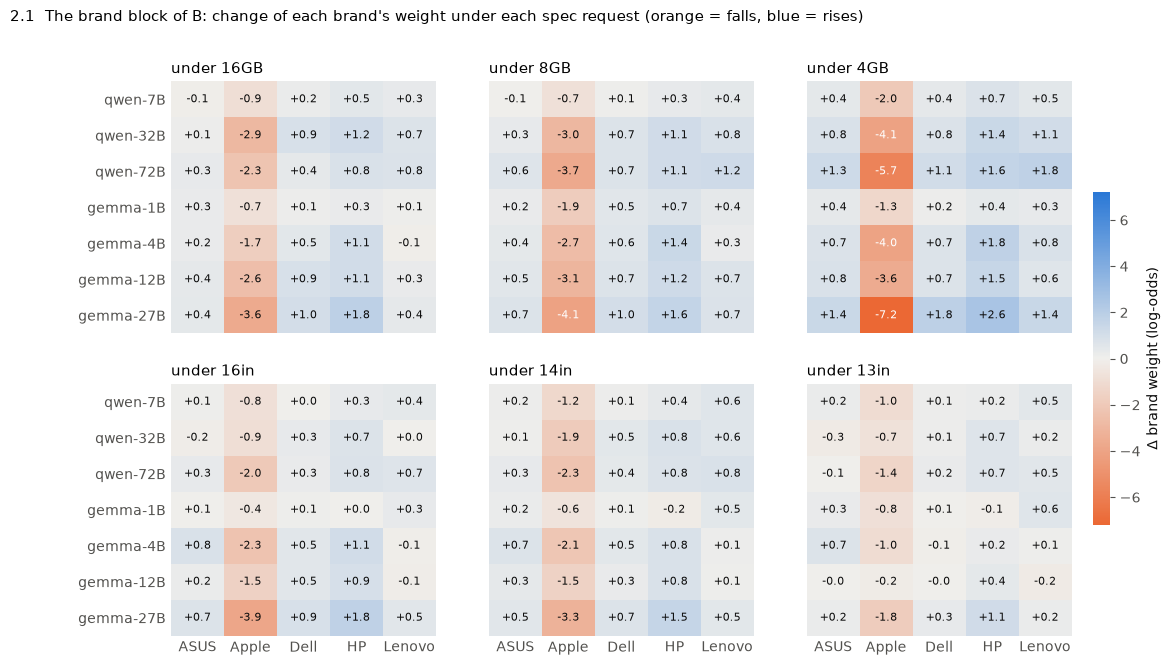

Apple is the most negative cell of its row in 41 of 42 rows
ram=16GB        Apple column: -3.6 … -0.7   HP column: +0.3 … +1.8
ram=8GB         Apple column: -4.1 … -0.7   HP column: +0.3 … +1.6
ram=4GB         Apple column: -7.2 … -1.3   HP column: +0.4 … +2.6
screen=16-inch  Apple column: -3.9 … -0.4   HP column: +0.0 … +1.8
screen=14-inch  Apple column: -3.3 … -0.6   HP column: -0.2 … +1.5
screen=13-inch  Apple column: -1.8 … -0.2   HP column: -0.1 … +1.1


In [4]:
from matplotlib.colors import LinearSegmentedColormap
DIV = LinearSegmentedColormap.from_list("div", [ORANGE, "#f0efec", BLUE])     # orange = falls, gray = 0, blue = rises
REQ = ["ram=16GB", "ram=8GB", "ram=4GB", "screen=16-inch", "screen=14-inch", "screen=13-inch"]
BB = {c: pd.DataFrame({m: R[(m, c)].w["brand"] - R[(m, "none")].w["brand"] for m in QG}).T[BRANDS] for c in REQ}
vmax = max(np.abs(b.values).max() for b in BB.values())
fig, axes = plt.subplots(2, 3, figsize=(14, 7.2), sharex=True, sharey=True)
for ax, c in zip(axes.flat, REQ):
    b = BB[c]
    im = ax.imshow(b.values, cmap=DIV, vmin=-vmax, vmax=vmax, aspect="auto")
    for i in range(b.shape[0]):
        for j in range(b.shape[1]):
            v = b.values[i, j]
            ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.55 * vmax else INK)
    ax.set_xticks(range(len(BRANDS)), BRANDS); ax.set_yticks(range(len(QG)), QG)
    ax.tick_params(length=0); [sp.set_visible(False) for sp in ax.spines.values()]
    ax.set_title(f"under {short(c)}", loc="left")
cb = fig.colorbar(im, ax=axes, shrink=0.6, pad=0.02); cb.set_label("Δ brand weight (log-odds)"); cb.outline.set_visible(False)
fig.suptitle("2.1  The brand block of B: change of each brand's weight under each spec request (orange = falls, blue = rises)", x=0.01, ha="left", fontsize=11)
fig.savefig(f"{FIG}/05_2a_B_brand_block.png", dpi=150, bbox_inches="tight"); plt.show()
print("Apple is the most negative cell of its row in", sum((BB[c].idxmin(axis=1) == "Apple").sum() for c in REQ), "of", len(REQ) * len(QG), "rows")
for c in REQ: print(f"{c:15} Apple column: {BB[c]['Apple'].min():+.1f} … {BB[c]['Apple'].max():+.1f}   HP column: {BB[c]['HP'].min():+.1f} … {BB[c]['HP'].max():+.1f}")

- **The Apple column jumps out**: Apple is the most negative cell of its row in **41 of 42** rows. Under RAM requests it
  falls by −0.7 … −7.2 (biggest under `4GB`: gemma-27B −7.2, qwen-72B −5.7); under screen requests by −0.2 … −3.9.
- **Every other brand rises a little**, HP (the least liked) the most: up to +2.6 under `4GB`. The brand taste gets
  flatter, and the favourite pays for it.
- **RAM requests move brand more than screen requests**, and `13-inch` the least (Apple −0.2 … −1.8).
- So the Apple decay **is** in B, plainly. The next two figures ask how much of it one κ per request explains, and
  what is left.

Does one number per request (κ, the same for every brand) explain this block? Below: every brand in every
one-requirement spec run (dot), its no-contract weight against its change. A line through 0 with slope −κ is pure
shrinkage.

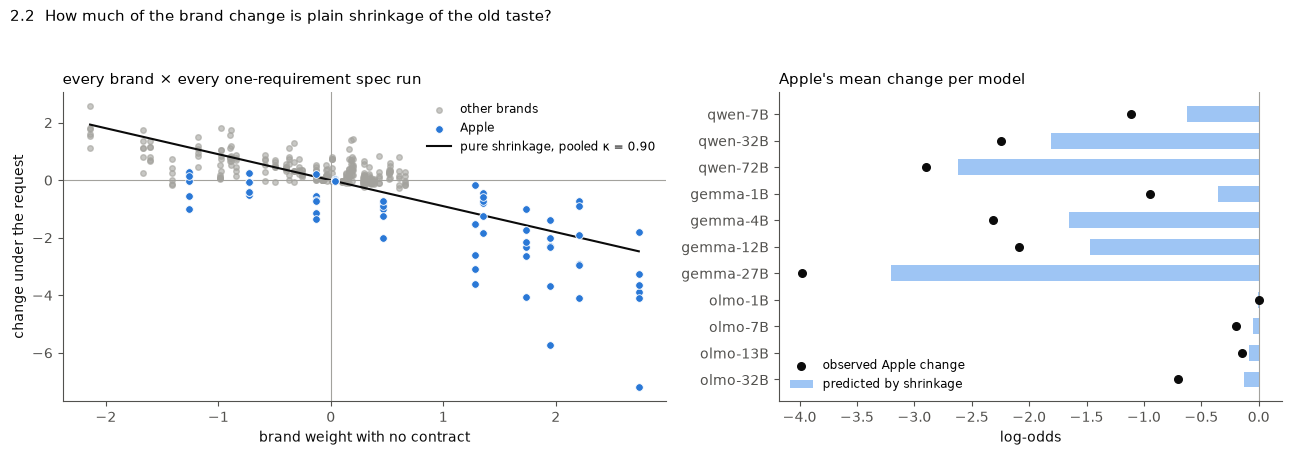

share of the brand change explained by shrinkage, per run: median 0.73 | IQR [0.35, 0.88]
Apple's extra fall beyond shrinkage (mean residual):
model
qwen-7B     -0.49
qwen-32B    -0.43
qwen-72B    -0.28
gemma-1B    -0.59
gemma-4B    -0.67
gemma-12B   -0.61
gemma-27B   -0.78
olmo-1B      0.01
olmo-7B     -0.15
olmo-13B    -0.06
olmo-32B    -0.58
Apple is the biggest faller in 51 of 66 runs


In [5]:
rows = []
for (m, c), r in R.items():
    p = parse(c)
    if len(p) != 1 or "brand" in p or m == "qwen-0.5B": continue
    a = R[(m, "none")].w["brand"]; d = r.w["brand"] - a
    k = -float(d @ a / (a @ a))
    for b in BRANDS:
        rows.append(dict(model=m, c=c, brand=b, a=a[b], d=d[b], shrink=-k * a[b], resid=d[b] + k * a[b]))
AP = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
oth = AP[AP.brand != "Apple"]; app = AP[AP.brand == "Apple"]
ax.scatter(oth.a, oth.d, s=16, color=GRAY, alpha=0.6, label="other brands")
ax.scatter(app.a, app.d, s=30, color=BLUE, edgecolor="white", linewidth=0.6, label="Apple", zorder=3)
xx = np.linspace(AP.a.min(), AP.a.max(), 2); kk = -float(AP.d @ AP.a / (AP.a @ AP.a))
ax.plot(xx, -kk * xx, color=INK, lw=1.5, label=f"pure shrinkage, pooled κ = {kk:.2f}")
ax.axhline(0, color=GRAY, lw=0.8); ax.axvline(0, color=GRAY, lw=0.8)
ax.set_xlabel("brand weight with no contract"); ax.set_ylabel("change under the request"); ax.legend(frameon=False, fontsize=8.5)
ax.set_title("every brand × every one-requirement spec run", loc="left")
ax = axes[1]
g = AP[AP.brand == "Apple"].groupby("model")[["d", "shrink", "resid"]].mean().reindex([m for m in REAL])
y = np.arange(len(g))
ax.barh(y, g.shrink, 0.6, color="#9ec5f4", label="predicted by shrinkage")
ax.scatter(g.d, y, color=INK, s=30, zorder=3, label="observed Apple change")
ax.axvline(0, color=GRAY, lw=0.8); ax.set_yticks(y, g.index); ax.invert_yaxis(); ax.legend(frameon=False, fontsize=8.5, loc="lower left")
ax.set_title("Apple's mean change per model", loc="left"); ax.set_xlabel("log-odds")
fig.suptitle("2.2  How much of the brand change is plain shrinkage of the old taste?", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.94)); fig.savefig(f"{FIG}/05_2_apple_shrinkage.png", dpi=150); plt.show()
share = AP.groupby(["model", "c"]).apply(lambda s: 1 - (s.resid ** 2).sum() / (s.d ** 2).sum())
print("share of the brand change explained by shrinkage, per run: median", round(share.median(), 2), "| IQR", share.quantile([.25, .75]).round(2).tolist())
print("Apple's extra fall beyond shrinkage (mean residual):"); print(AP[AP.brand == "Apple"].groupby("model").resid.mean().reindex(REAL).round(2).to_string())
print("Apple is the biggest faller in", int(AP.loc[AP.groupby(["model", "c"]).d.idxmin()].brand.eq("Apple").sum()), "of", AP.groupby(["model", "c"]).ngroups, "runs")

- **Shrinkage explains most of the brand change**: median **79%** per run (middle half 51–88%), with κ allowed above 1
  (the order turns). The brand liked most falls most.
- **Apple is the biggest faller in 45 of 50** one-requirement spec runs.
- **But Apple also falls extra**, beyond the shared shrinkage, in 10 of 11 models (−0.2 … −0.8 log-odds; olmo-1B is the
  exception). Even OLMo, where Apple is not the favourite, shows it. Section 2b shows where this extra comes from.

### 2b. Where does Apple's fall come from? The laptops that meet the request vs the ones that miss it

Apple's weight is the mean over all 9 Apple laptops. Split them: the Apple laptops that **meet** the RAM request, and
the ones that **miss** it. Apple's lead = mean utility of those Apple laptops minus the mean of the other brands' laptops
with the same RAM. If the request only shrank the brand taste, both leads would shrink alike.

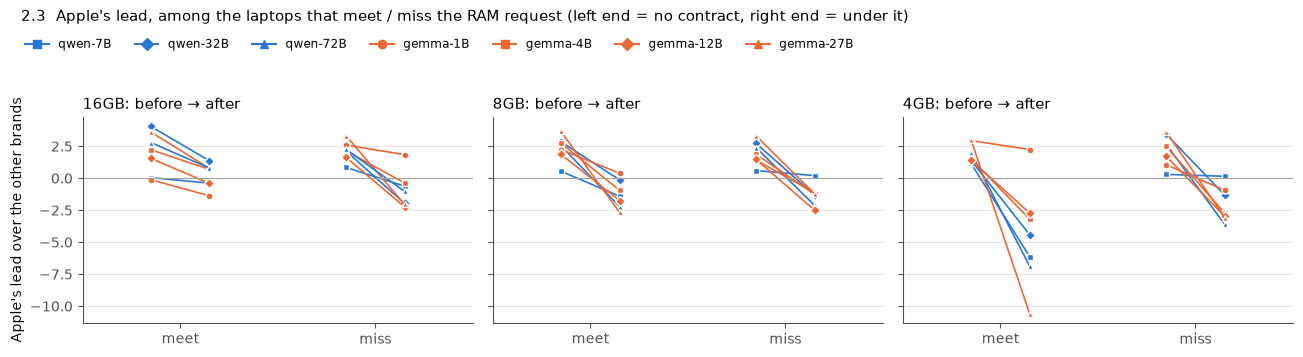

                         meets                        misses                  
when               no contract under the request no contract under the request
c        model                                                                
ram=16GB gemma-12B         1.5              -0.4         1.6              -2.2
         gemma-1B         -0.1              -1.4         2.6               1.8
         gemma-27B         3.6               0.8         3.3              -2.0
         gemma-4B          2.2               0.7         2.1              -0.4
         qwen-32B          4.0               1.4         2.1              -2.0
         qwen-72B          2.8               0.8         2.3              -1.0
         qwen-7B           0.0              -0.4         0.8              -0.6
ram=4GB  gemma-12B         1.4              -2.7         1.7              -3.0
         gemma-1B          2.9               2.2         1.1              -0.9
         gemma-27B         3.0             -10.6    

In [6]:
rows = []
for (m, c), r in R.items():
    p = parse(c)
    if list(p) != ["ram"] or m not in QG: continue
    for name, rr in [("no contract", R[(m, "none")]), ("under the request", r)]:
        u = pd.Series(rr.u, index=pd.MultiIndex.from_tuples(LAPTOPS, names=FEATS))
        t = u.groupby(["brand", "ram"]).mean().unstack()
        lead = t.loc["Apple"] - t.drop("Apple").mean()
        rows.append(dict(model=m, c=c, when=name, meets=lead[p["ram"]], misses=lead.drop(p["ram"]).mean()))
AL = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, c in zip(axes, ["ram=16GB", "ram=8GB", "ram=4GB"]):
    s = AL[AL.c == c]
    for j, (col, lab) in enumerate([("meets", "Apple laptops that MEET it"), ("misses", "Apple laptops that MISS it")]):
        for _, r0 in s[s.when == "no contract"].iterrows():
            r1 = s[(s.when == "under the request") & (s.model == r0.model)].iloc[0]
            st = model_style(r0.model)
            ax.plot([j - 0.15, j + 0.15], [r0[col], r1[col]], color=st["color"], lw=1.2, marker=st["marker"], ms=5, mec="white")
    ax.axhline(0, color=GRAY, lw=0.8); ax.set_xticks([0, 1], ["meet", "miss"]); ax.set_xlim(-0.5, 1.5)
    ax.set_title(f"{short(c)}: before → after", loc="left"); ax.grid(axis="y", color=GRID, lw=0.8)
axes[0].set_ylabel("Apple's lead over the other brands")
fig.suptitle("2.3  Apple's lead, among the laptops that meet / miss the RAM request (left end = no contract, right end = under it)", x=0.01, ha="left", fontsize=11)
handles = [plt.Line2D([], [], marker=model_style(m)["marker"], color=model_style(m)["color"], label=m) for m in QG]
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.005, 0.93), ncol=7, frameon=False, fontsize=8.5)
fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(f"{FIG}/05_2b_apple_meet_miss.png", dpi=150); plt.show()
print(AL.pivot_table(index=["c", "model"], columns="when", values=["meets", "misses"]).round(1).to_string())

- **This is not where the Apple fall comes from — it is how it splits** across the Apple laptops. B gives every Apple
  laptop the same change (one number per cell of 2.1); the data split it by RAM level.
- **Under `16GB`: a miss-penalty.** Among the 16GB laptops Apple still leads in 4 of 7 models (qwen-32B +4.0 → +1.4).
  Among the 4GB and 8GB laptops — the ones that **miss** the request — Apple drops below the other brands in 6 of 7
  (qwen-32B +2.1 → −2.0).
- **Under `4GB`: a budget turn.** The Apple laptops that **meet** the request fall hardest: qwen-72B +2.0 → −6.9,
  gemma-27B +3.0 → −10.6; negative in 6 of 7. "I want 4GB" reads as "I am on a budget", and Apple does not fit that.
- **Why B cannot show the split**: U = (a + Bᵀx)ᵀz is linear in z, so Apple-4GB and Apple-16GB get the same Apple change.
  Punishing "Apple **and** 4GB" needs a product z_Apple · z_4GB: a term quadratic in z (open in grum_formalization §12).

## 3. How hard is a request? Predicting obedience from the no-contract weights

Notebook 02 §2 found the requested level's lead after the contract ≈ intercept + slope × lead before. That is a
prediction **from the base weights alone**, once the two numbers per feature are known. Here: is the request obeyed
(the requested level beats every other level, with everything else equal), against how far behind it started?

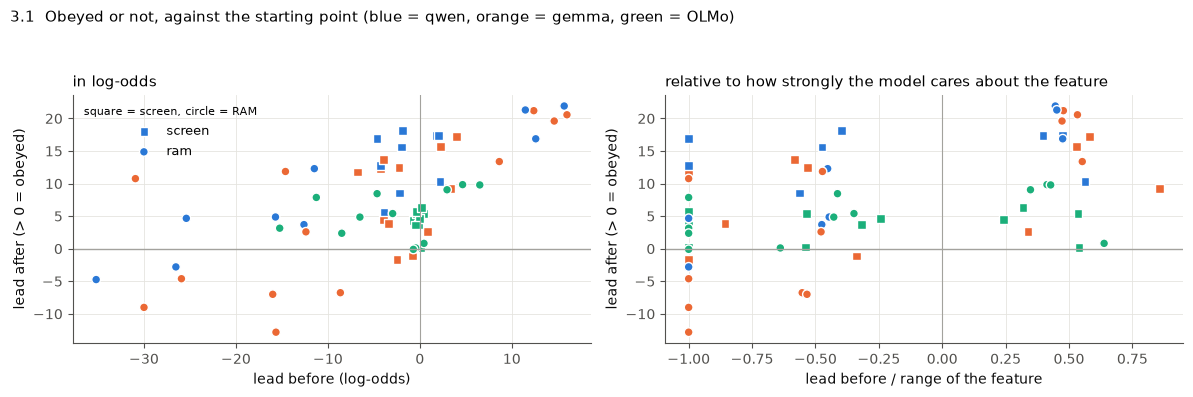

{'ram': 0.76, 'screen': 0.94}
RAM requests not obeyed:
    model   l     m0     m1  m0_rel
  qwen-7B 4GB -26.53  -2.80   -1.00
 qwen-32B 4GB -35.19  -4.74   -1.00
 gemma-1B 4GB -15.64 -12.82   -1.00
 gemma-4B 4GB -29.99  -9.01   -1.00
gemma-12B 4GB -25.92  -4.61   -1.00
 gemma-1B 8GB  -8.64  -6.76   -0.55
 gemma-4B 8GB -16.00  -7.00   -0.53
  olmo-1B 4GB  -0.71  -0.10   -1.00
RAM, obeyed vs m0_rel:
        min   max
obeyed           
False  -1.0 -0.53
True   -1.0  0.64


In [7]:
rows = []
for (m, c), r in R.items():
    p = parse(c)
    if len(p) != 1 or m == "qwen-0.5B" or "brand" in p: continue
    (f, l), = p.items(); a = R[(m, "none")].w[f]; w = r.w[f]
    rng0 = R[(m, "none")].w[f].max() - R[(m, "none")].w[f].min()
    rows.append(dict(model=m, f=f, l=l, m0=a[l] - a.drop(l).max(), m1=w[l] - w.drop(l).max(), range0=rng0))
OB = pd.DataFrame(rows); OB["obeyed"] = OB.m1 > 0; OB["m0_rel"] = OB.m0 / OB.range0
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, lab in [(axes[0], "m0", "lead before (log-odds)"), (axes[1], "m0_rel", "lead before / range of the feature")]:
    for f, mk in [("screen", "s"), ("ram", "o")]:
        s = OB[OB.f == f]
        ax.scatter(s[col], s.m1, s=40, marker=mk, color=[FAMC[FAMILY[x]] for x in s.model], edgecolor="white", label=f)
    ax.axhline(0, color=GRAY, lw=1); ax.axvline(0, color=GRAY, lw=0.8)
    ax.set_xlabel(lab); ax.set_ylabel("lead after (> 0 = obeyed)"); ax.grid(color=GRID, lw=0.6)
axes[0].legend(frameon=False, fontsize=9, title="square = screen, circle = RAM", title_fontsize=8)
axes[0].set_title("in log-odds", loc="left"); axes[1].set_title("relative to how strongly the model cares about the feature", loc="left")
fig.suptitle("3.1  Obeyed or not, against the starting point (blue = qwen, orange = gemma, green = OLMo)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.93)); fig.savefig(f"{FIG}/05_3_obedience.png", dpi=150); plt.show()
print(OB.groupby("f").obeyed.mean().round(2).to_dict())
print("RAM requests not obeyed:"); print(OB[(OB.f == "ram") & ~OB.obeyed][["model", "l", "m0", "m1", "m0_rel"]].round(2).to_string(index=False))
print("RAM, obeyed vs m0_rel:"); print(OB[OB.f == "ram"].groupby("obeyed").m0_rel.describe()[["min", "max"]].round(2).to_string())

- **Screen requests are obeyed in 92% of runs, RAM requests in 72%.** Every failure is a RAM request for a level far
  below the favourite (`4GB`, or `8GB` in gemma-1/4B).
- **But the starting point does not decide who pays.** For `4GB` (the worst level, relative lead −1 in every model),
  two of the big models obey (qwen-72B, gemma-27B) and five do not, with overlapping starting leads.
- So the base weights tell **which** requests are risky, not **whether** a given model pays. Paying is a trait of the
  model, and costs one hard run per model to learn.

## 4. Do louder models push harder? (compliance vs the feature's scale)

Per model: the push ρ and flattening σ of notebook 02 (one per feature), against how strongly that model cares about
the feature with no contract (its range). If compliance were just "the model's own scale", ρ would grow in proportion.

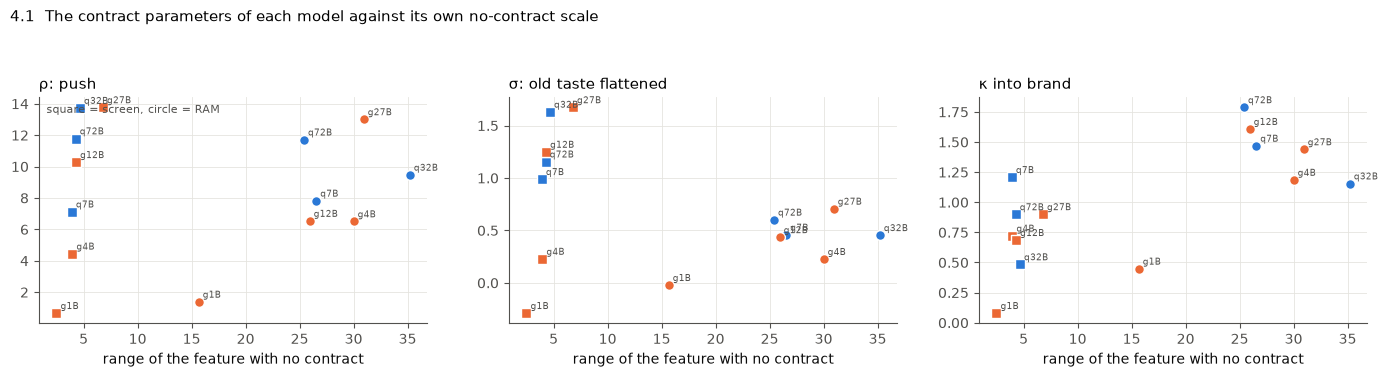

screen {'rho': np.float64(0.93), 'sigma': np.float64(0.96), 'kappa_brand': np.float64(0.14)} | rho/range: [1.83, 2.95, 2.77, 0.27, 1.13, 2.4, 2.03]
ram {'rho': np.float64(0.46), 'sigma': np.float64(0.36), 'kappa_brand': np.float64(-0.21)} | rho/range: [0.29, 0.27, 0.46, 0.09, 0.22, 0.25, 0.42]


In [8]:
rows = []
for m in QG:
    a = R[(m, "none")].w
    for f in ["screen", "ram"]:
        P = fit_struct(a, [(f, l, R[(m, f"{f}={l}")].w) for l in LEVELS[f]])
        rows.append(dict(model=m, f=f, rho=P["rho"][f], sigma=P["sigma"][f], range0=a[f].max() - a[f].min(),
                         kappa_brand=P["kappa"][(f, "brand")]))
SC = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, lab in zip(axes, ["rho", "sigma", "kappa_brand"], ["ρ: push", "σ: old taste flattened", "κ into brand"]):
    for f, mk in [("screen", "s"), ("ram", "o")]:
        s = SC[SC.f == f]
        for _, r in s.iterrows():
            st = model_style(r.model)
            ax.scatter(r.range0, r[col], s=50, marker=mk, color=st["color"], edgecolor="white")
            ax.annotate(r.model.replace("gemma-", "g").replace("qwen-", "q"), (r.range0, r[col]), xytext=(3, 3), textcoords="offset points", fontsize=6.5, color=INK2)
    ax.set_xlabel("range of the feature with no contract"); ax.set_title(lab, loc="left"); ax.grid(color=GRID, lw=0.6)
axes[0].text(0.02, 0.97, "square = screen, circle = RAM", transform=axes[0].transAxes, fontsize=8, va="top", color=INK2)
fig.suptitle("4.1  The contract parameters of each model against its own no-contract scale", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.92)); fig.savefig(f"{FIG}/05_4_scale.png", dpi=150); plt.show()
for f in ["screen", "ram"]:
    s = SC[SC.f == f]
    print(f, {c: round(spearmanr(s.range0, s[c])[0], 2) for c in ["rho", "sigma", "kappa_brand"]}, "| rho/range:", (s.rho / s.range0).round(2).tolist())

- **Louder models push harder**: ρ grows with the feature's no-contract range (Spearman **0.93** for screen, 0.46 for RAM).
- **Relative to the taste, the RAM push is much weaker**: ρ / range is 1.1–3.0 for screen (gemma-1B 0.27 aside) but only
  **0.09–0.46** for RAM. A RAM request moves the model by a small share of how much it cares about RAM — which is why
  RAM requests fail and screen requests do not.
- **Leakage into brand does not follow the scale** (Spearman 0.14 / −0.21).

## Summary: what the no-contract model tells, and what needs a contract run

| | predictable from the no-contract weights? |
|---|---|
| anything at all, in theory | **no** — B is not identified at x = 0 (section 1) |
| which brand falls under a spec request | **mostly**: the top brand, by shrinkage (79% of the change; Apple 45/50) |
| Apple's extra fall beyond shrinkage | **no** — but a free B row catches it (−0.2 … −0.8 extra) |
| how the fall splits between Apple laptops that meet / miss the request | **no**, and not even B: needs a z × z term |
| which requests are risky | **yes**: the ones far below the favourite, on a high-priority feature |
| the size of the push | **roughly**: it grows with the feature's scale |
| whether a model pays for a hard request | **no** — a model trait (one hard run per model) |

So with the inductive bias of section 1, the minimal design per model is: the no-contract run, one run per feature
(preferably the hard level), and one compound run.